# 02eventmaps: the Choi-wan haze event in maps and numbers

Part A of PF5 (direct export). Uses the files from `01event` (no downloads, except two small coastline files the first time).

| Section | What |
|---|---|
| 2 | Snapshot map of 3 October: GEOS-FP and CAMS PM2.5 side by side, with fires, winds and Choi-wan's track |
| 3 | Do the two models agree? PM2.5 over time in four regions |
| 4 | What is the haze made of? PM2.5 parts per region |
| 5 | Smoke or sea salt? Total PM2.5 split into smoke and sea salt at the snapshot time |
| 6 | Smoke outlines and numbers: smoke area in the Pacific corridor, how close the smoke came to the storm, smoke and sea salt around the storm |
| 7 | Animation frames and a GIF of the whole event (smoke PM2.5) |

Outputs go to `data/processed/event/`: figures, `event_metrics.csv`, `model_regions.csv` and the frames.

PM2.5 levels used for colours and outlines: 15 micrograms per cubic metre is the WHO 24-hour guideline; 55.5 is where the US Air Quality Index turns "unhealthy".

**Why smoke only from Section 5 on.** Total PM2.5 near a typhoon is dominated by sea salt that the storm's own winds throw up from the ocean (about 95% within 500 km of Choi-wan's centre). That would make "PM2.5 near the storm" rise simply because the storm got stronger. Smoke PM2.5 (organic + brown + black carbon from GEOS-FP) isolates the fire haze. CAMS only gives total PM2.5 in our download, so the model comparison (Section 3) uses totals.

## Section 0: settings

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "raw" / "event"
OUT_DIR = PROJECT_DIR / "data" / "processed" / "event"
FIG_DIR = OUT_DIR / "figures"
FRAME_DIR = OUT_DIR / "frames"
COAST_DIR = PROJECT_DIR / "data" / "raw" / "naturalearth"

SNAPSHOT_TIME = "2026-10-03 04:30"  # <- time of the snapshot map (UTC, GEOS-FP steps are at hh:30)

WHO_24H = 15.0  # <- WHO 24-hour PM2.5 guideline, micrograms per m3
UNHEALTHY = 55.5  # <- US AQI "unhealthy" starts here
NEAR_STORM_KM = 500  # <- radius around the storm centre for "near the storm"
SMOKE_EDGE = 5.0  # <- smoke PM2.5 (micrograms per m3) that marks the edge of the smoke plume

# Regions as (west, east, south, north) in degrees
REGIONS = {}
REGIONS["Sumatra"] = (95.0, 106.0, -6.0, 4.0)  # <-
REGIONS["Kalimantan"] = (108.0, 118.5, -4.5, 2.0)  # <-
REGIONS["Eastern Indonesia"] = (119.0, 141.0, -9.0, 2.0)  # <- Sulawesi, Maluku, Papua
REGIONS["Pacific corridor"] = (128.0, 150.0, 3.0, 18.0)  # <- open ocean between eastern Indonesia and the storm

MAP_EXTENT = (90.0, 160.0, -15.0, 45.0)  # <- (west, east, south, north) of the maps

# VISUAL: PM2.5 colour steps (micrograms per m3) and one-hue colour ramp
PM_LEVELS = [0, 5, 10, 15, 25, 35, 55.5, 75, 100, 150, 250, 500, 1000]  # <-
PM_CMAP = "Oranges"  # <- VISUAL: sequential, light = clean air, dark = heavy haze
SMOKE_LEVELS = [0, 1, 2, 5, 10, 15, 25, 35, 55.5, 100, 250, 500, 1000]  # <- VISUAL: smoke PM2.5 colour steps
WIND_STEP = 12  # <- VISUAL: draw one wind arrow every n grid points
FIRE_COLOR = "#2a78d6"  # <- VISUAL: hotspots in blue so they stand out on the orange haze
TRACK_COLOR = "#0b0b0b"  # <- VISUAL: typhoon track
GIF_FPS = 6  # <- VISUAL: frames per second of the event GIF
FRAME_DPI = 100  # <- VISUAL: frame resolution (100 gives about 1000 x 860 pixels)

## Section 1: imports and data

In [2]:
import json
import warnings
import requests
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from PIL import Image

warnings.filterwarnings("ignore", message="Ambiguous reference date string")
for d in [OUT_DIR, FIG_DIR, FRAME_DIR, COAST_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Categorical colours (fixed order, colour-blind checked)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams["figure.facecolor"] = "#fcfcfb"
plt.rcParams["axes.facecolor"] = "#fcfcfb"
plt.rcParams["axes.edgecolor"] = "#a8a7a2"
plt.rcParams["axes.grid"] = False
plt.rcParams["font.size"] = 10

In [3]:
# GEOS-FP: one file per variable, merged; surface mass converted from kg/m3 to micrograms/m3
geos = xr.merge([xr.open_dataset(f) for f in sorted(RAW_DIR.glob("geosfp_*.nc"))])
SURFACE_VARS = ["pm25", "dusmass25", "sssmass25", "bcsmass", "ocsmass", "brsmass", "so4smass", "nismass25", "nh4smass"]
for v in SURFACE_VARS:
    geos[v] = geos[v] * 1e9
geos["smoke"] = geos["ocsmass"] + geos["brsmass"] + geos["bcsmass"]
geos["smoke_col"] = (geos["occmass"] + geos["brcmass"] + geos["bccmass"]) * 1e6
GT = pd.to_datetime(geos.time.values)
print("GEOS-FP:", len(GT), "steps,", GT[0], "to", GT[-1], " grid", geos.sizes["lat"], "x", geos.sizes["lon"])

# CAMS: runs (00, 12 UTC) x lead times (0, 3, 6, 9 h) turned into one time axis
cams_raw = xr.open_dataset(RAW_DIR / "cams_event.nc").sortby("latitude")
pm_c = cams_raw["pm2p5"].transpose("forecast_reference_time", "forecast_period", "latitude", "longitude").values * 1e9
ct = (cams_raw.forecast_reference_time.values[:, None] + cams_raw.forecast_period.values[None, :]).ravel()
cams = xr.DataArray(pm_c.reshape(-1, cams_raw.sizes["latitude"], cams_raw.sizes["longitude"]), coords={"time": ct, "lat": cams_raw.latitude.values, "lon": cams_raw.longitude.values}, dims=["time", "lat", "lon"], name="pm25").sortby("time")
CT = pd.to_datetime(cams.time.values)
print("CAMS:", len(CT), "steps,", CT[0], "to", CT[-1], " grid", cams.sizes["lat"], "x", cams.sizes["lon"])

# ERA5 wind at 850 hPa (3-hourly)
era = xr.concat([xr.open_dataset(f) for f in sorted(RAW_DIR.glob("era5_levels_*.nc"))], dim="valid_time").sortby("latitude")
u850 = era["u"].sel(pressure_level=850)
v850 = era["v"].sel(pressure_level=850)
ET = pd.to_datetime(era.valid_time.values)
print("ERA5 850 hPa:", len(ET), "steps")

# FIRMS: VIIRS only for the maps (finer than MODIS), low-confidence detections dropped
fires = pd.read_csv(RAW_DIR / "firms_event.csv", low_memory=False)
fires = fires[fires["source"].str.startswith("VIIRS") & (fires["confidence"] != "l")].copy()
fires["date"] = pd.to_datetime(fires["acq_date"])
print("VIIRS hotspots (nominal and high confidence):", len(fires))

# Choi-wan track (6-hourly and some 3-hourly points), with values interpolated to every GEOS-FP step
track = pd.read_csv(RAW_DIR / "choiwan_track.csv")
track["time"] = pd.to_datetime(track["ISO_TIME"])
track["wind"] = pd.to_numeric(track["USA_WIND"], errors="coerce")
track["pres"] = pd.to_numeric(track["USA_PRES"], errors="coerce")
T0 = pd.Timestamp("2026-01-01")
tsec = (track["time"] - T0).dt.total_seconds().values
gsec = (GT - T0).total_seconds().values
inside = (GT >= track["time"].iloc[0]) & (GT <= track["time"].iloc[-1])
storm = pd.DataFrame({"time": GT})
storm["lat"] = np.where(inside, np.interp(gsec, tsec, track["LAT"]), np.nan)
storm["lon"] = np.where(inside, np.interp(gsec, tsec, track["LON"]), np.nan)
storm["wind"] = np.where(inside, np.interp(gsec, tsec, track["wind"]), np.nan)
print("Track:", len(track), "points,", track["time"].iloc[0], "to", track["time"].iloc[-1], " peak", track["wind"].max(), "kt")

GEOS-FP: 80 steps, 2026-09-28 01:30:00 to 2026-10-07 22:30:00  grid 241 x 225
CAMS: 80 steps, 2026-09-28 00:00:00 to 2026-10-07 21:00:00  grid 150 x 176
ERA5 850 hPa: 80 steps
VIIRS hotspots (nominal and high confidence): 379719
Track: 59 points, 2026-09-30 00:00:00 to 2026-10-07 06:00:00  peak 134 kt


In [4]:
# Coastlines and land borders from Natural Earth (downloaded once from GitHub, about 2 MB)
NE_BASE = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/"
NE_FILES = ["ne_50m_coastline.geojson", "ne_50m_admin_0_boundary_lines_land.geojson"]
for name in NE_FILES:
    path = COAST_DIR / name
    if not path.exists():
        r = requests.get(NE_BASE + name, timeout=120)
        print(name, "download, HTTP status:", r.status_code)
        path.write_bytes(r.content)


def load_lines(path):
    lines = []
    for feat in json.loads(path.read_text(encoding="utf8"))["features"]:
        geom = feat["geometry"]
        parts = geom["coordinates"] if geom["type"] == "MultiLineString" else [geom["coordinates"]]
        lines += [np.array(p) for p in parts]
    return lines


COAST = load_lines(COAST_DIR / NE_FILES[0])
BORDERS = load_lines(COAST_DIR / NE_FILES[1])


def draw_base(ax, extent=MAP_EXTENT):
    for line in COAST:
        ax.plot(line[:, 0], line[:, 1], color="#52514e", lw=0.5)
    for line in BORDERS:
        ax.plot(line[:, 0], line[:, 1], color="#8a8984", lw=0.4, ls=":")
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")
    ax.tick_params(labelsize=8, colors="#52514e")


def draw_track(ax, until):
    past = track[track["time"] <= until]
    ax.plot(track["LON"], track["LAT"], color=TRACK_COLOR, lw=0.8, ls="--", alpha=0.35)
    ax.plot(past["LON"], past["LAT"], color=TRACK_COLOR, lw=1.6)
    row = storm[storm["time"] == until]
    if len(row) and not np.isnan(row["lat"].iloc[0]):
        ax.scatter(row["lon"], row["lat"], s=90, marker="o", facecolor="none", edgecolor=TRACK_COLOR, lw=2, zorder=5)


PM_NORM = BoundaryNorm(PM_LEVELS, plt.get_cmap(PM_CMAP).N, extend="max")
SMOKE_NORM = BoundaryNorm(SMOKE_LEVELS, plt.get_cmap(PM_CMAP).N, extend="max")
print("Coastline pieces:", len(COAST), " border pieces:", len(BORDERS))

ne_50m_coastline.geojson download, HTTP status: 200
ne_50m_admin_0_boundary_lines_land.geojson download, HTTP status: 200
Coastline pieces: 1429  border pieces: 393


## Section 2: snapshot map

GEOS-FP values are 3-hour means centred on the time shown; CAMS values are instantaneous every 3 hours, so the snapshot uses the mean of the two CAMS steps either side (for 04:30, the 03:00 and 06:00 steps). Hotspots are all VIIRS detections of that day; wind arrows are ERA5 at 850 hPa (about 1.5 km up), the level that carries most of the smoke.

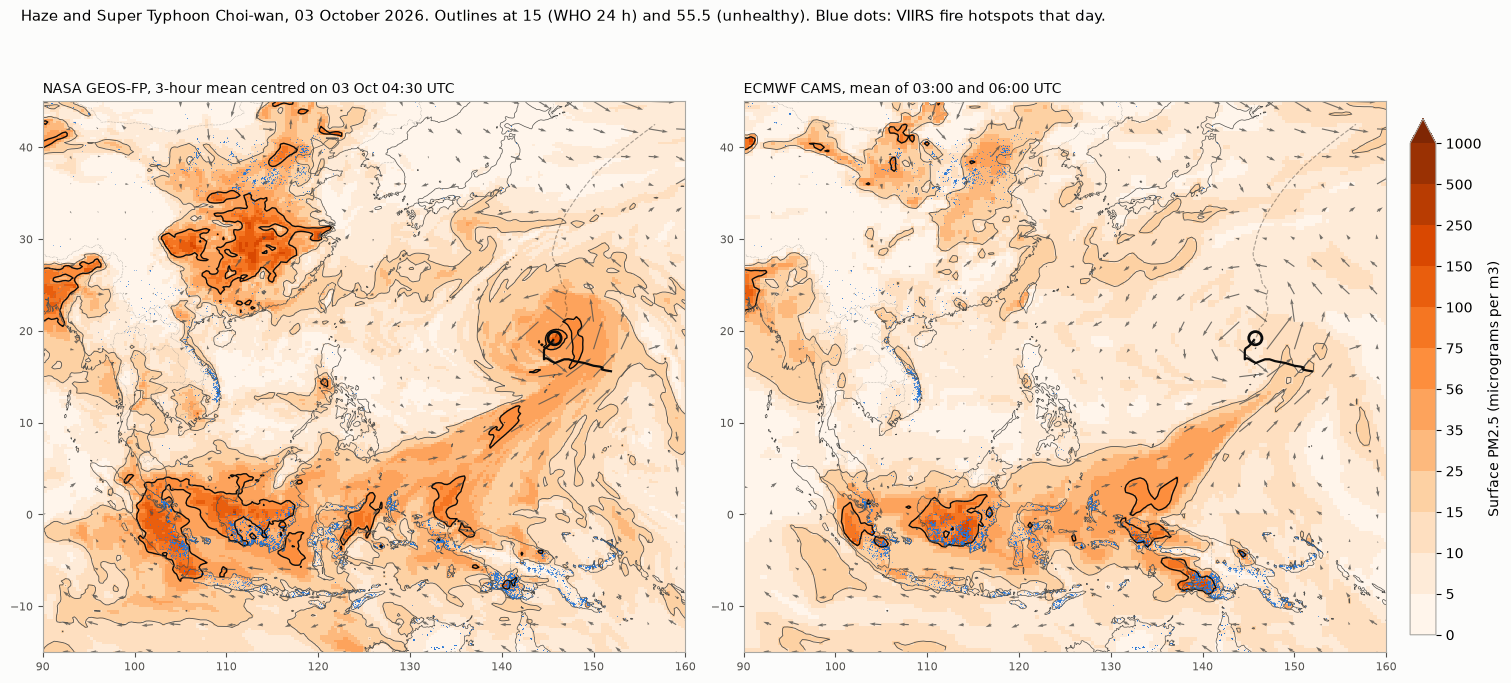

Saved .\data\processed\event\figures\snapshot_models.png


In [5]:
snap = pd.Timestamp(SNAPSHOT_TIME)
gi = int(np.abs(GT - snap).argmin())
c_near = np.sort(np.argsort(np.abs(CT - snap))[:2])
ei = int(np.abs(ET - snap).argmin())
geos_snap = geos["pm25"].isel(time=gi)
cams_snap = cams.isel(time=c_near).mean("time")
fires_snap = fires[fires["date"] == snap.normalize()]

fig, axes = plt.subplots(1, 2, figsize=(15, 7.2), constrained_layout=True)
panels = [(geos_snap, f"NASA GEOS-FP, 3-hour mean centred on {GT[gi]:%d %b %H:%M} UTC"), (cams_snap, f"ECMWF CAMS, mean of {CT[c_near[0]]:%H:%M} and {CT[c_near[1]]:%H:%M} UTC")]
for ax, (field, title) in zip(axes, panels):
    mesh = ax.pcolormesh(field.lon, field.lat, field, cmap=PM_CMAP, norm=PM_NORM, shading="auto")
    ax.contour(field.lon, field.lat, field, levels=[WHO_24H, UNHEALTHY], colors=["#52514e", "#0b0b0b"], linewidths=[0.6, 1.0])
    draw_base(ax)
    ax.scatter(fires_snap["longitude"], fires_snap["latitude"], s=0.3, color=FIRE_COLOR, alpha=0.6, lw=0)
    s = WIND_STEP
    ax.quiver(u850.longitude[::s], u850.latitude[::s], u850.isel(valid_time=ei)[::s, ::s], v850.isel(valid_time=ei)[::s, ::s], color="#52514e", scale=600, width=0.0018, alpha=0.8)
    draw_track(ax, GT[gi])
    ax.set_title(title, fontsize=10, loc="left", color="#0b0b0b")
cb = fig.colorbar(mesh, ax=axes, shrink=0.75, pad=0.01, ticks=PM_LEVELS)
cb.set_label("Surface PM2.5 (micrograms per m3)")
fig.suptitle(f"Haze and Super Typhoon Choi-wan, {GT[gi]:%d %B %Y}. Outlines at {WHO_24H:g} (WHO 24 h) and {UNHEALTHY:g} (unhealthy). Blue dots: VIIRS fire hotspots that day.", fontsize=11, x=0.01, ha="left")
fig.savefig(FIG_DIR / "snapshot_models.png", dpi=110)
plt.show()
print("Saved", FIG_DIR / "snapshot_models.png")

## Section 3: do the two models agree?

Area-weighted mean surface PM2.5 in each region, every 3 hours. The two models use different fire inputs and chemistry, so exact agreement is not expected; what matters is whether they tell the same story about where and when the haze is.

The pattern correlation compares the two maps over the whole box at each time step (CAMS is first interpolated onto the GEOS-FP grid): 1 means the same pattern, 0 means unrelated.

Pattern correlation of log PM2.5 over the box: median 0.66, range 0.59 to 0.74
                   mean            max        
model              CAMS GEOS-FP   CAMS GEOS-FP
region                                        
Eastern Indonesia  29.1    29.8   46.8    43.0
Kalimantan         66.2    53.6  138.8    70.2
Pacific corridor   13.6    19.1   17.3    24.3
Sumatra            28.1    45.9   45.6    59.7


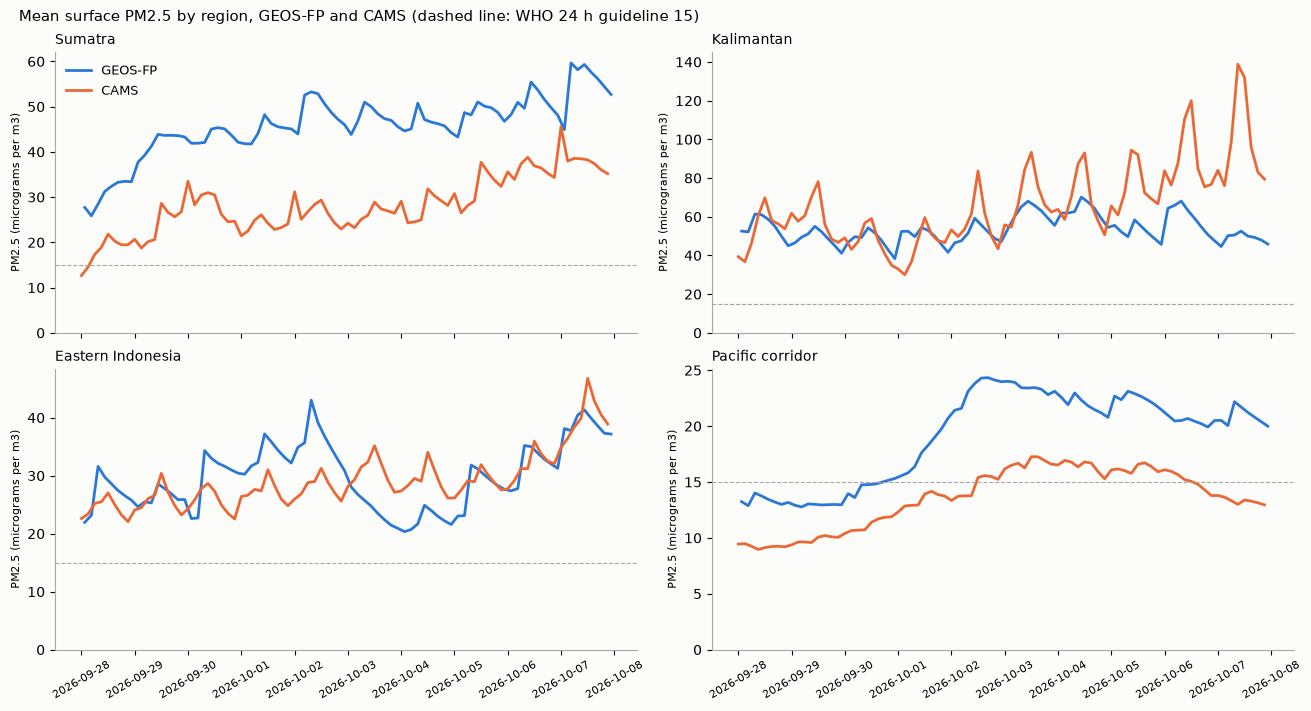

In [6]:
def region_mean(da, box):
    sub = da.sel(lon=slice(box[0], box[1]), lat=slice(box[2], box[3]))
    w = np.cos(np.deg2rad(sub.lat))
    return sub.weighted(w).mean(["lat", "lon"])


rows = []
for name, box in REGIONS.items():
    g = region_mean(geos["pm25"], box).to_series()
    c = region_mean(cams, box).to_series()
    rows.append(pd.DataFrame({"time": g.index, "region": name, "model": "GEOS-FP", "pm25": g.values}))
    rows.append(pd.DataFrame({"time": c.index, "region": name, "model": "CAMS", "pm25": c.values}))
model_regions = pd.concat(rows, ignore_index=True)
model_regions.to_csv(OUT_DIR / "model_regions.csv", index=False)

cams_on_geos = cams.interp(time=geos.time, lat=geos.lat, lon=geos.lon)
gv = np.log1p(geos["pm25"].values.reshape(len(GT), -1))
cv = np.log1p(cams_on_geos.values.reshape(len(GT), -1))
ok = ~np.isnan(cv)
pattern_r = np.array([np.corrcoef(gv[i][ok[i]], cv[i][ok[i]])[0, 1] if ok[i].sum() > 100 else np.nan for i in range(len(GT))])
print(f"Pattern correlation of log PM2.5 over the box: median {np.nanmedian(pattern_r):.2f}, range {np.nanmin(pattern_r):.2f} to {np.nanmax(pattern_r):.2f}")

summary = model_regions.groupby(["region", "model"])["pm25"].agg(["mean", "max"]).round(1).unstack("model")
print(summary)

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, constrained_layout=True)
for ax, name in zip(axes.ravel(), REGIONS):
    for k, model in enumerate(["GEOS-FP", "CAMS"]):
        d = model_regions[(model_regions["region"] == name) & (model_regions["model"] == model)]
        ax.plot(d["time"], d["pm25"], color=SERIES[k], lw=2, label=model)
    ax.axhline(WHO_24H, color="#a8a7a2", lw=0.8, ls="--")
    ax.set_title(name, loc="left", fontsize=10)
    ax.set_ylabel("PM2.5 (micrograms per m3)", fontsize=8)
    ax.set_ylim(bottom=0)
    ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].legend(frameon=False, fontsize=9)
for ax in axes[1]:
    ax.tick_params(axis="x", rotation=30, labelsize=8)
fig.suptitle(f"Mean surface PM2.5 by region, GEOS-FP and CAMS (dashed line: WHO 24 h guideline {WHO_24H:g})", x=0.01, ha="left", fontsize=11)
fig.savefig(FIG_DIR / "models_by_region.png", dpi=110)
plt.show()

## Section 4: what is the haze made of?

GEOS-FP surface PM2.5 split into its parts, averaged over the event window in each region. Smoke from fires shows up as organic carbon, brown carbon and black carbon. The bar total can differ a little from GEOS-FP's own `pm25` (black tick), because NASA's PM2.5 recipe applies conversion factors to some parts.

                   Organic carbon  Brown carbon  Black carbon  Sulfate  Nitrate  Ammonium  Dust  Sea salt  GEOS-FP pm25  smoke share %
Sumatra                      10.4          18.5           2.1      7.3      0.3       2.1   0.3       4.9          45.9           67.7
Kalimantan                   11.7          26.4           2.5      6.3      0.2       1.6   0.3       4.6          53.6           75.8
Eastern Indonesia             3.4          14.2           1.2      2.4      0.0       0.5   0.2       7.9          29.8           62.9
Pacific corridor              1.5           5.7           0.5      2.2      0.0       0.3   0.1       8.8          19.1           40.3


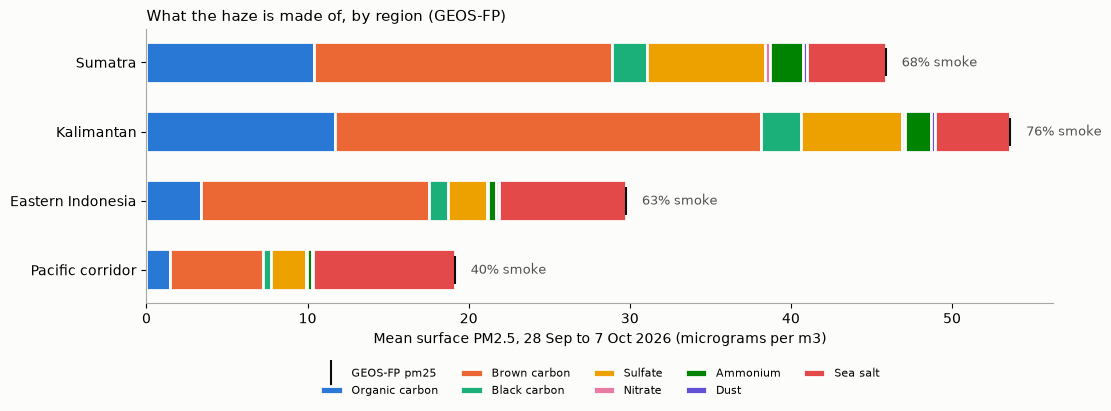

In [7]:
PARTS = [("ocsmass", "Organic carbon"), ("brsmass", "Brown carbon"), ("bcsmass", "Black carbon"), ("so4smass", "Sulfate"), ("nismass25", "Nitrate"), ("nh4smass", "Ammonium"), ("dusmass25", "Dust"), ("sssmass25", "Sea salt")]
comp = pd.DataFrame({label: [float(region_mean(geos[v], box).mean()) for box in REGIONS.values()] for v, label in PARTS}, index=list(REGIONS))
comp["GEOS-FP pm25"] = [float(region_mean(geos["pm25"], box).mean()) for box in REGIONS.values()]
comp["smoke share %"] = 100 * comp[["Organic carbon", "Brown carbon", "Black carbon"]].sum(axis=1) / comp[[p[1] for p in PARTS]].sum(axis=1)
print(comp.round(1).to_string())
comp.round(3).to_csv(OUT_DIR / "composition_regions.csv")

fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
left = np.zeros(len(comp))
for k, (v, label) in enumerate(PARTS):
    ax.barh(comp.index, comp[label], left=left, color=SERIES[k], edgecolor="#fcfcfb", linewidth=2, height=0.6, label=label)
    left = left + comp[label].values
ax.scatter(comp["GEOS-FP pm25"], comp.index, marker="|", s=400, color="#0b0b0b", zorder=5, label="GEOS-FP pm25")
for i, name in enumerate(comp.index):
    ax.text(left[i] + 1, i, f"{comp['smoke share %'].iloc[i]:.0f}% smoke", va="center", fontsize=9, color="#52514e")
ax.invert_yaxis()
ax.set_xlabel("Mean surface PM2.5, 28 Sep to 7 Oct 2026 (micrograms per m3)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(ncol=5, frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.set_title("What the haze is made of, by region (GEOS-FP)", loc="left", fontsize=11)
fig.savefig(FIG_DIR / "composition_regions.png", dpi=110)
plt.show()

## Section 5: smoke or sea salt?

GEOS-FP at the snapshot time: total surface PM2.5, the sea salt part, the smoke part (organic + brown + black carbon), and smoke in the whole air column (smoke can travel above the surface layer). This is the honest version of the nullschool picture: the streamer into the storm is smoke, while the bright ring around the eye is sea salt from the storm's winds.

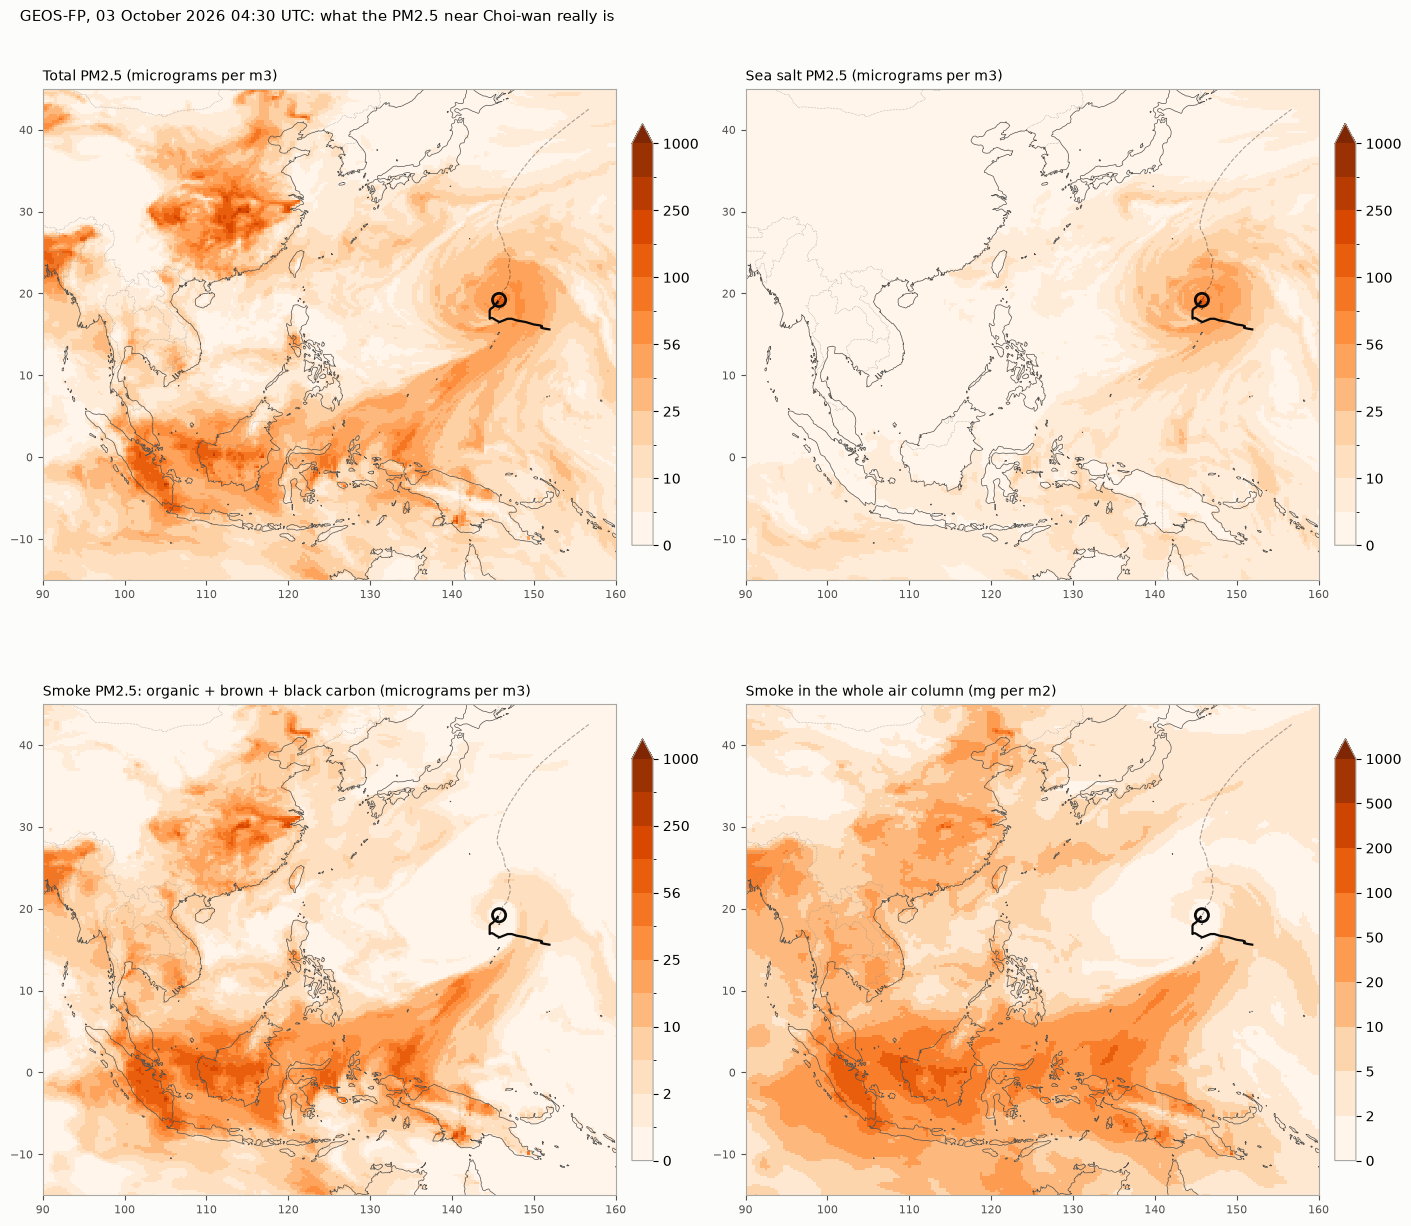

Pacific corridor at snapshot, total PM2.5 : mean  23.9, max   80.9 micrograms per m3
Pacific corridor at snapshot, sea salt    : mean  12.7, max   57.4 micrograms per m3
Pacific corridor at snapshot, smoke       : mean   8.5, max   64.3 micrograms per m3


In [8]:
x = geos.isel(time=gi)
panels = [(x["pm25"], "Total PM2.5 (micrograms per m3)", PM_NORM), (x["sssmass25"], "Sea salt PM2.5 (micrograms per m3)", PM_NORM), (x["smoke"], "Smoke PM2.5: organic + brown + black carbon (micrograms per m3)", SMOKE_NORM), (x["smoke_col"], "Smoke in the whole air column (mg per m2)", BoundaryNorm([0, 2, 5, 10, 20, 50, 100, 200, 500, 1000], 256, extend="max"))]
fig, axes = plt.subplots(2, 2, figsize=(14, 12.5), constrained_layout=True)
for ax, (field, title, norm) in zip(axes.ravel(), panels):
    mesh = ax.pcolormesh(field.lon, field.lat, field, cmap=PM_CMAP, norm=norm, shading="auto")
    draw_base(ax)
    draw_track(ax, GT[gi])
    ax.set_title(title, loc="left", fontsize=10)
    fig.colorbar(mesh, ax=ax, shrink=0.7, pad=0.01)
fig.suptitle(f"GEOS-FP, {GT[gi]:%d %B %Y %H:%M} UTC: what the PM2.5 near Choi-wan really is", x=0.01, ha="left", fontsize=11)
fig.savefig(FIG_DIR / "smoke_vs_seasalt.png", dpi=110)
plt.show()
cb_ = REGIONS["Pacific corridor"]
corr = (x.lon >= cb_[0]) & (x.lon <= cb_[1]) & (x.lat >= cb_[2]) & (x.lat <= cb_[3])
for v, label in [("pm25", "total PM2.5"), ("sssmass25", "sea salt"), ("smoke", "smoke")]:
    print(f"Pacific corridor at snapshot, {label:12s}: mean {float(x[v].where(corr).mean()):5.1f}, max {float(x[v].where(corr).max()):6.1f} micrograms per m3")

## Section 6: smoke outlines and numbers

For every 3-hour step:

- **Corridor smoke area**: area of the Pacific corridor box with smoke PM2.5 at or above the plume edge (Section 0), and at or above the WHO level (km2).
- **Corridor smoke centre**: smoke-weighted centre of the plume in the corridor (where the streamer sits).
- **Storm to smoke**: distance from Choi-wan's centre to the nearest grid cell with smoke at or above the plume edge (km).
- **Near the storm**: mean smoke PM2.5, sea salt PM2.5 and smoke column within the radius set in Section 0 around the storm centre.

The charts share the time axis but each has its own scale (no double axes).

In [9]:
R_EARTH = 6371.0
lat2d, lon2d = np.meshgrid(geos.lat.values, geos.lon.values, indexing="ij")
cell_km2 = (R_EARTH ** 2) * np.deg2rad(0.25) * np.deg2rad(0.3125) * np.cos(np.deg2rad(lat2d))
cb_ = REGIONS["Pacific corridor"]
in_corr = (lon2d >= cb_[0]) & (lon2d <= cb_[1]) & (lat2d >= cb_[2]) & (lat2d <= cb_[3])


def km_from(lat0, lon0):
    p1 = np.deg2rad(lat0)
    p2 = np.deg2rad(lat2d)
    dphi = p2 - p1
    dlmb = np.deg2rad(lon2d - lon0)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlmb / 2) ** 2
    return 2 * R_EARTH * np.arcsin(np.sqrt(a))


smoke_all = geos["smoke"].values
salt_all = geos["sssmass25"].values
col_all = geos["smoke_col"].values
rec = []
for i, t in enumerate(GT):
    sm = smoke_all[i]
    plume = sm >= SMOKE_EDGE
    corr_plume = plume & in_corr
    w = np.where(corr_plume, sm * cell_km2, 0.0)
    row = {"time": t}
    row["corridor_smoke_area_km2"] = float(cell_km2[corr_plume].sum())
    row["corridor_smoke_who_km2"] = float(cell_km2[(sm >= WHO_24H) & in_corr].sum())
    row["corridor_centre_lat"] = float((w * lat2d).sum() / w.sum()) if w.sum() > 0 else np.nan
    row["corridor_centre_lon"] = float((w * lon2d).sum() / w.sum()) if w.sum() > 0 else np.nan
    row["box_smoke_area_km2"] = float(cell_km2[plume].sum())
    slat = storm["lat"].iloc[i]
    slon = storm["lon"].iloc[i]
    row["storm_lat"] = slat
    row["storm_lon"] = slon
    row["storm_wind_kt"] = storm["wind"].iloc[i]
    if np.isnan(slat):
        for k in ["storm_to_smoke_km", "near_storm_smoke", "near_storm_seasalt", "near_storm_smoke_col"]:
            row[k] = np.nan
    else:
        dist = km_from(slat, slon)
        near = dist <= NEAR_STORM_KM
        wk = cell_km2[near]
        row["storm_to_smoke_km"] = float(dist[plume].min()) if plume.any() else np.nan
        row["near_storm_smoke"] = float((sm[near] * wk).sum() / wk.sum())
        row["near_storm_seasalt"] = float((salt_all[i][near] * wk).sum() / wk.sum())
        row["near_storm_smoke_col"] = float((col_all[i][near] * wk).sum() / wk.sum())
    rec.append(row)
metrics = pd.DataFrame(rec)
metrics.to_csv(OUT_DIR / "event_metrics.csv", index=False)

peak = metrics.loc[metrics["corridor_smoke_area_km2"].idxmax()]
closest = metrics.loc[metrics["storm_to_smoke_km"].idxmin()]
smokiest = metrics.loc[metrics["near_storm_smoke"].idxmax()]
print(f"Largest smoke area in the corridor: {peak['corridor_smoke_area_km2'] / 1e3:,.0f} thousand km2 at {peak['time']:%d %b %H:%M} UTC")
print(f"Closest approach of the smoke plume edge to the storm centre: {closest['storm_to_smoke_km']:,.0f} km at {closest['time']:%d %b %H:%M} UTC")
print(f"Highest mean smoke PM2.5 within {NEAR_STORM_KM} km of the storm: {smokiest['near_storm_smoke']:.1f} micrograms per m3 at {smokiest['time']:%d %b %H:%M} UTC (sea salt then {smokiest['near_storm_seasalt']:.1f})")
show = metrics.iloc[::8][["time", "corridor_smoke_area_km2", "storm_to_smoke_km", "near_storm_smoke", "near_storm_seasalt", "near_storm_smoke_col", "storm_wind_kt"]].copy()
show["corridor_smoke_area_km2"] = (show["corridor_smoke_area_km2"] / 1e3).round(0)
show = show.rename(columns={"corridor_smoke_area_km2": "corridor_smoke_thousand_km2"})
print(show.set_index("time").round(1).to_string())

Largest smoke area in the corridor: 2,725 thousand km2 at 06 Oct 10:30 UTC
Closest approach of the smoke plume edge to the storm centre: 202 km at 04 Oct 07:30 UTC
Highest mean smoke PM2.5 within 500 km of the storm: 2.4 micrograms per m3 at 03 Oct 19:30 UTC (sea salt then 44.9)
                     corridor_smoke_thousand_km2  storm_to_smoke_km  near_storm_smoke  near_storm_seasalt  near_storm_smoke_col  storm_wind_kt
time                                                                                                                                          
2026-09-28 01:30:00                       1461.0                NaN               NaN                 NaN                   NaN            NaN
2026-09-29 01:30:00                       1280.0                NaN               NaN                 NaN                   NaN            NaN
2026-09-30 01:30:00                       1203.0              332.2               1.1                11.6                   1.8           26.0
2026-

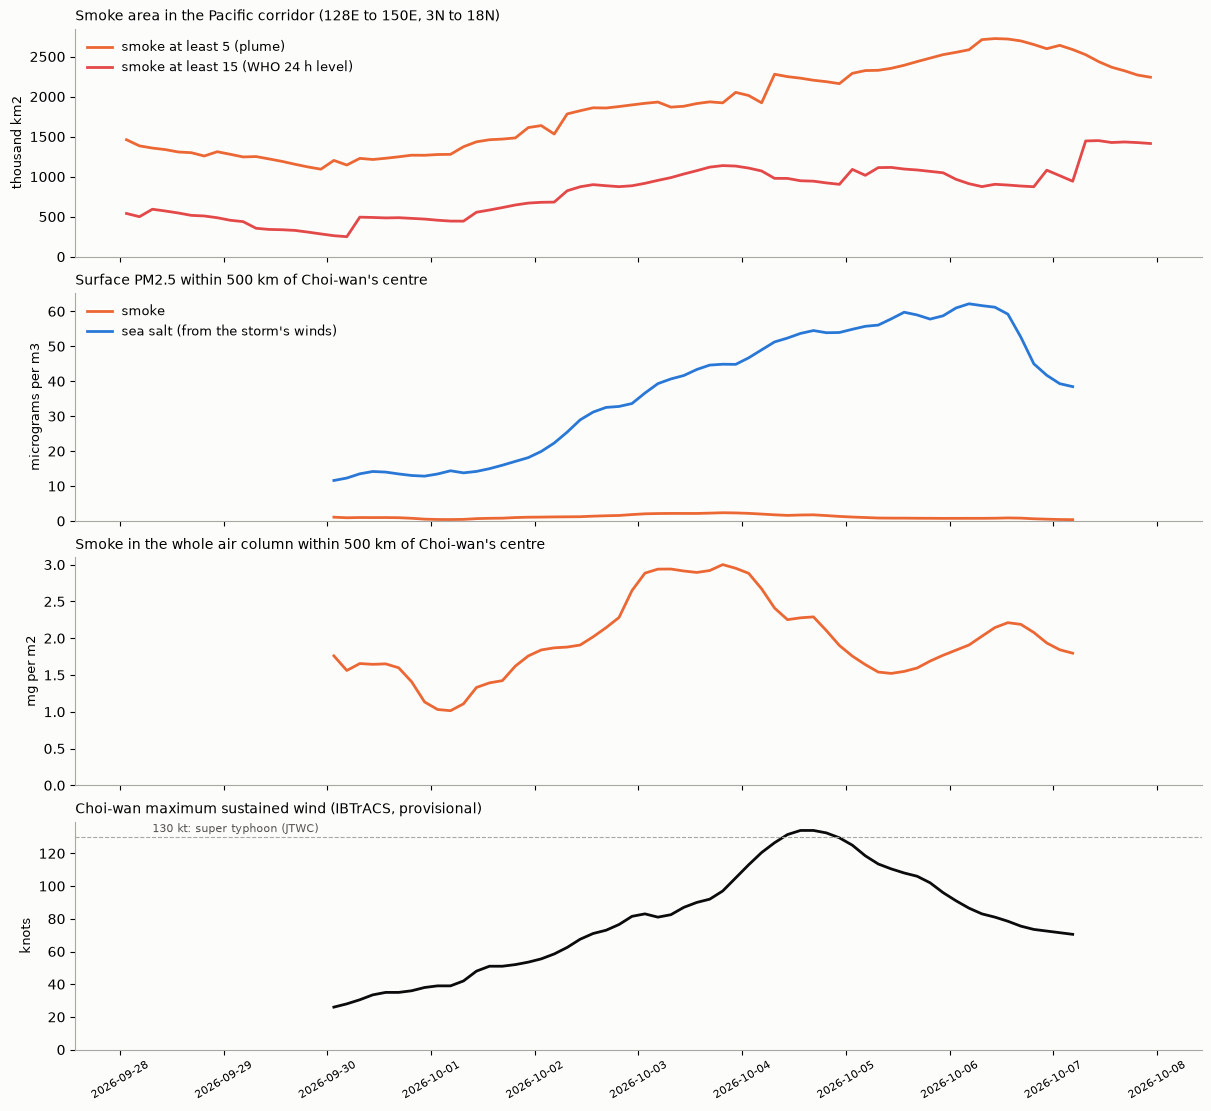

In [10]:
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True, constrained_layout=True)
ax = axes[0]
ax.plot(metrics["time"], metrics["corridor_smoke_area_km2"] / 1e3, color=SERIES[1], lw=2, label=f"smoke at least {SMOKE_EDGE:g} (plume)")
ax.plot(metrics["time"], metrics["corridor_smoke_who_km2"] / 1e3, color=SERIES[7], lw=2, label=f"smoke at least {WHO_24H:g} (WHO 24 h level)")
ax.set_ylabel("thousand km2", fontsize=9)
ax.set_title("Smoke area in the Pacific corridor (128E to 150E, 3N to 18N)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9)
ax = axes[1]
ax.plot(metrics["time"], metrics["near_storm_smoke"], color=SERIES[1], lw=2, label="smoke")
ax.plot(metrics["time"], metrics["near_storm_seasalt"], color=SERIES[0], lw=2, label="sea salt (from the storm's winds)")
ax.set_ylabel("micrograms per m3", fontsize=9)
ax.set_title(f"Surface PM2.5 within {NEAR_STORM_KM} km of Choi-wan's centre", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9)
ax = axes[2]
ax.plot(metrics["time"], metrics["near_storm_smoke_col"], color=SERIES[1], lw=2)
ax.set_ylabel("mg per m2", fontsize=9)
ax.set_title(f"Smoke in the whole air column within {NEAR_STORM_KM} km of Choi-wan's centre", loc="left", fontsize=10)
ax = axes[3]
ax.plot(metrics["time"], metrics["storm_wind_kt"], color=TRACK_COLOR, lw=2)
ax.axhline(130, color="#a8a7a2", lw=0.8, ls="--")
ax.text(metrics["time"].iloc[2], 133, "130 kt: super typhoon (JTWC)", fontsize=8, color="#52514e")
ax.set_ylabel("knots", fontsize=9)
ax.set_title("Choi-wan maximum sustained wind (IBTrACS, provisional)", loc="left", fontsize=10)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylim(bottom=0)
axes[3].tick_params(axis="x", rotation=30, labelsize=8)
fig.savefig(FIG_DIR / "event_metrics.png", dpi=110)
plt.show()

## Section 7: animation frames and GIF

Smoke PM2.5 (organic + brown + black carbon), with outlines at the plume edge and the WHO level. One PNG per 3-hour step in `data/processed/event/frames/`, plus `event_smoke.gif`. These are quick-look frames for checking the story; the web version later will draw the data live on a globe.

Takes about 1 to 3 minutes.

In [11]:
fire_days = {d: g for d, g in fires.groupby("date")}
frame_files = []
s = WIND_STEP
for i, t in enumerate(GT):
    fig, ax = plt.subplots(figsize=(10, 8.6), constrained_layout=True)
    field = geos["smoke"].isel(time=i)
    mesh = ax.pcolormesh(field.lon, field.lat, field, cmap=PM_CMAP, norm=SMOKE_NORM, shading="auto")
    ax.contour(field.lon, field.lat, field, levels=[SMOKE_EDGE, WHO_24H], colors=["#52514e", "#0b0b0b"], linewidths=[0.6, 1.0])
    draw_base(ax)
    day_fires = fire_days.get(t.normalize())
    if day_fires is not None:
        ax.scatter(day_fires["longitude"], day_fires["latitude"], s=0.3, color=FIRE_COLOR, alpha=0.6, lw=0)
    ei = int(np.abs(ET - t).argmin())
    ax.quiver(u850.longitude[::s], u850.latitude[::s], u850.isel(valid_time=ei)[::s, ::s], v850.isel(valid_time=ei)[::s, ::s], color="#52514e", scale=600, width=0.0018, alpha=0.8)
    draw_track(ax, t)
    wind = storm["wind"].iloc[i]
    storm_text = f"   Choi-wan {wind:.0f} kt" if not np.isnan(wind) else ""
    ax.set_title(f"{t:%d %b %Y %H:%M} UTC   smoke PM2.5 (GEOS-FP){storm_text}", loc="left", fontsize=11)
    cb = fig.colorbar(mesh, ax=ax, shrink=0.7, pad=0.01, ticks=SMOKE_LEVELS)
    cb.set_label("smoke PM2.5, micrograms per m3", fontsize=9)
    path = FRAME_DIR / f"frame_{i:03d}.png"
    fig.savefig(path, dpi=FRAME_DPI)
    plt.close(fig)
    frame_files.append(path)
print("Frames written:", len(frame_files))

images = [Image.open(p).convert("P", palette=Image.ADAPTIVE, colors=128) for p in frame_files]
gif_path = OUT_DIR / "event_smoke.gif"
images[0].save(gif_path, save_all=True, append_images=images[1:], duration=int(1000 / GIF_FPS), loop=0)
print(f"GIF: {gif_path} ({gif_path.stat().st_size / 1e6:.1f} MB)")

Frames written: 80
GIF: .\data\processed\event\event_smoke.gif (10.5 MB)


___
**END**